1. Prepare output folders.
2. Extract corresponding 256 × 256 patches from all three bands.
3. Exclude patches dominated by invalid black borders.
4. Preserve each patch's CRS and correctly updated geospatial transform.
5. Create a CSV manifest with scene IDs, patch coordinates, and file paths.
6. Split the dataset by scene into training, validation, and testing sets.
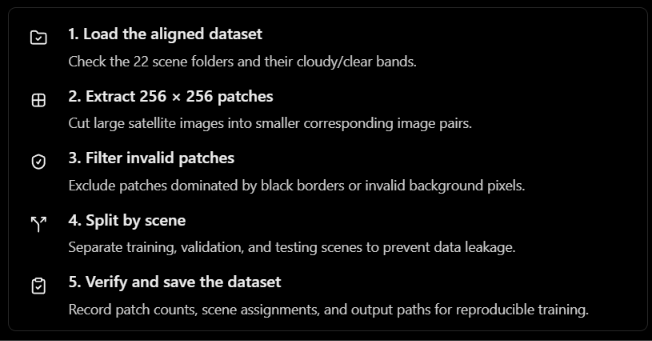

In [13]:
from pathlib import Path

ROOT = Path(r"E:\Rasengan\Cloud-Removal")
ALIGNED_DIR = ROOT / "data" / "aligned"
PATCH_DIR = ROOT / "data" / "diffcr_patches"

scenes = sorted(
    p.name for p in ALIGNED_DIR.iterdir()
    if p.is_dir()
    and all((p / kind).is_dir() for kind in ["cloudy", "clear"])
)

print("Scenes found:", len(scenes))
print("Scenes:", scenes)
print("Aligned data exists:", ALIGNED_DIR.exists())

Scenes found: 22
Scenes: ['ahemadabad1', 'ahemadabad2', 'chennai1', 'gumla1', 'gumla2', 'gumla3', 'jaipur1', 'jaipur2', 'jaipur3', 'katiyana1', 'katiyana2', 'mandi1', 'nzb1', 'nzb2', 'patna1', 'sambalpur1', 'sambalpur2', 'shilong', 'tirupati1', 'uttarpradesh1', 'yavatmal1', 'yavatmal2']
Aligned data exists: True


In [14]:
from pathlib import Path

for kind in ["cloudy", "clear"]:
    for scene in scenes:
        (PATCH_DIR / kind / scene).mkdir(parents=True, exist_ok=True)

print("Output folders created for", len(scenes), "scenes.")

Output folders created for 22 scenes.


In [16]:
import numpy as np
import rasterio
from rasterio.windows import Window

scene = "ahemadabad1"
PATCH_SIZE = 256
STRIDE = 256
MIN_VALID_FRACTION = 0.90

saved = 0
rejected = 0

band_names = ["BAND2.TIF", "BAND3.TIF", "BAND4.TIF"]

with rasterio.open(ALIGNED_DIR / scene / "cloudy" / band_names[0]) as ref:
    height, width = ref.height, ref.width

for row in range(0, height - PATCH_SIZE + 1, STRIDE):
    for col in range(0, width - PATCH_SIZE + 1, STRIDE):
        window = Window(col, row, PATCH_SIZE, PATCH_SIZE)
        cloudy_arrays, clear_arrays = [], []
        cloudy_profile = None

        for band in band_names:
            with rasterio.open(ALIGNED_DIR / scene / "cloudy" / band) as src:
                cloudy_arrays.append(src.read(1, window=window))
                if band == band_names[0]:
                    cloudy_profile = src.profile.copy()

            with rasterio.open(ALIGNED_DIR / scene / "clear" / band) as src:
                clear_arrays.append(src.read(1, window=window))

        cloudy_valid = np.any(np.stack(cloudy_arrays) != 0, axis=0)
        clear_valid = np.any(np.stack(clear_arrays) != 0, axis=0)
        valid_fraction = np.mean(cloudy_valid & clear_valid)

        if valid_fraction < MIN_VALID_FRACTION:
            rejected += 1
            continue

        filename = f"r{row}_c{col}.tif"
        profile = cloudy_profile.copy()
        profile.update(
            height=PATCH_SIZE,
            width=PATCH_SIZE,
            count=3,
            transform=cloudy_profile["transform"] * rasterio.Affine.translation(col, row),
            compress="deflate"
        )

        for kind, arrays in [("cloudy", cloudy_arrays), ("clear", clear_arrays)]:
            out_path = PATCH_DIR / kind / scene / filename
            with rasterio.open(out_path, "w", **profile) as dst:
                dst.write(np.stack(arrays))
                dst.descriptions = tuple(band_names)

        saved += 1

print("Scene:", scene)
print("Saved patch pairs:", saved)
print("Rejected patch pairs:", rejected)
print("Total candidates:", saved + rejected)

Scene: ahemadabad1
Saved patch pairs: 3340
Rejected patch pairs: 1007
Total candidates: 4347


In [17]:
import rasterio
import numpy as np

path = PATCH_DIR / "cloudy" / "ahemadabad1" / "r0_c10240.tif"

with rasterio.open(path) as src:
    data = src.read()
    print("Min:", data.min())
    print("Max:", data.max())
    print("Mean:", data.mean())
    print("Nonzero pixels:", np.count_nonzero(data))
    print("Shape:", data.shape)

Min: 321
Max: 966
Mean: 623.0379689534506
Nonzero pixels: 196608
Shape: (3, 256, 256)


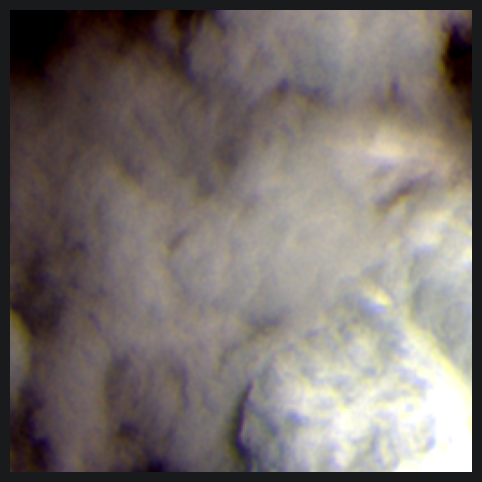

In [18]:
import matplotlib.pyplot as plt
import numpy as np
import rasterio

path = PATCH_DIR / "cloudy" / "ahemadabad1" / "r0_c10240.tif"

with rasterio.open(path) as src:
    img = src.read([3, 2, 1]).astype(np.float32)

rgb = np.moveaxis(img, 0, -1)
low, high = np.percentile(rgb, [2, 98])
rgb = np.clip((rgb - low) / (high - low + 1e-8), 0, 1)

plt.figure(figsize=(6, 6))
plt.imshow(rgb)
plt.axis("off")
plt.show()

In [19]:
import numpy as np
import rasterio
from rasterio.windows import Window

BANDS = ["BAND2.TIF", "BAND3.TIF", "BAND4.TIF"]
PATCH_SIZE = 256
STRIDE = 256
MIN_VALID_FRACTION = 0.90

total_saved = 0
total_rejected = 0

for scene in scenes:
    if scene == "ahemadabad1":
        continue  # Already extracted and verified

    paths = {
        kind: [ALIGNED_DIR / scene / kind / band for band in BANDS]
        for kind in ["cloudy", "clear"]
    }

    with rasterio.open(paths["cloudy"][0]) as ref:
        height, width = ref.height, ref.width

    with rasterio.open(paths["cloudy"][0]) as c0, \
         rasterio.open(paths["cloudy"][1]) as c1, \
         rasterio.open(paths["cloudy"][2]) as c2, \
         rasterio.open(paths["clear"][0]) as k0, \
         rasterio.open(paths["clear"][1]) as k1, \
         rasterio.open(paths["clear"][2]) as k2:

        cloudy_srcs = [c0, c1, c2]
        clear_srcs = [k0, k1, k2]

        saved = rejected = 0

        for row in range(0, height - PATCH_SIZE + 1, STRIDE):
            for col in range(0, width - PATCH_SIZE + 1, STRIDE):
                window = Window(col, row, PATCH_SIZE, PATCH_SIZE)

                cloudy = np.stack([s.read(1, window=window) for s in cloudy_srcs])
                clear = np.stack([s.read(1, window=window) for s in clear_srcs])

                cloudy_valid = np.any(cloudy != 0, axis=0)
                clear_valid = np.any(clear != 0, axis=0)
                valid_fraction = np.mean(cloudy_valid & clear_valid)

                if valid_fraction < MIN_VALID_FRACTION:
                    rejected += 1
                    continue

                name = f"r{row}_c{col}.tif"
                profile = c0.profile.copy()
                profile.update(
                    height=PATCH_SIZE,
                    width=PATCH_SIZE,
                    count=3,
                    transform=c0.window_transform(window),
                    compress="deflate"
                )

                for kind, data in [("cloudy", cloudy), ("clear", clear)]:
                    out = PATCH_DIR / kind / scene / name
                    with rasterio.open(out, "w", **profile) as dst:
                        dst.write(data)
                        dst.descriptions = tuple(BANDS)

                saved += 1

        total_saved += saved
        total_rejected += rejected
        print(f"{scene}: saved {saved}, rejected {rejected}")

print("\nRemaining scenes complete.")
print("Saved patch pairs:", total_saved)
print("Rejected candidates:", total_rejected)

ahemadabad2: saved 3524, rejected 961
chennai1: saved 3332, rejected 952
gumla1: saved 3442, rejected 968
gumla2: saved 3415, rejected 995
gumla3: saved 3430, rejected 980
jaipur1: saved 3444, rejected 972
jaipur2: saved 3493, rejected 987
jaipur3: saved 3447, rejected 969
katiyana1: saved 3473, rejected 947
katiyana2: saved 3527, rejected 958
mandi1: saved 3526, rejected 962
nzb1: saved 3441, rejected 969
nzb2: saved 3478, rejected 874
patna1: saved 3378, rejected 969
sambalpur1: saved 3406, rejected 1004
sambalpur2: saved 3445, rejected 1028
shilong: saved 3276, rejected 1008
tirupati1: saved 3395, rejected 952
uttarpradesh1: saved 3411, rejected 1005
yavatmal1: saved 3512, rejected 973
yavatmal2: saved 3416, rejected 994

Remaining scenes complete.
Saved patch pairs: 72211
Rejected candidates: 20427


In [20]:
from pathlib import Path

for kind in ["cloudy", "clear"]:
    total = sum(
        len(list((PATCH_DIR / kind / scene).glob("*.tif")))
        for scene in scenes
    )
    print(f"{kind.title()} patches: {total:,}")

Cloudy patches: 75,551
Clear patches: 75,551


In [21]:
import rasterio

checked = 0
errors = []

for scene in scenes:
    cloudy_dir = PATCH_DIR / "cloudy" / scene
    clear_dir = PATCH_DIR / "clear" / scene

    cloudy_files = {p.name for p in cloudy_dir.glob("*.tif")}
    clear_files = {p.name for p in clear_dir.glob("*.tif")}

    if cloudy_files != clear_files:
        errors.append(f"{scene}: filenames differ")
        continue

    for name in cloudy_files:
        with rasterio.open(cloudy_dir / name) as c, \
             rasterio.open(clear_dir / name) as k:
            if (c.shape != k.shape or c.crs != k.crs
                    or c.transform != k.transform):
                errors.append(f"{scene}/{name}: metadata mismatch")
        checked += 1

print("Pairs checked:", checked)
print("Errors:", len(errors))
if errors:
    print(*errors[:10], sep="\n")
else:
    print("All cloudy-clear patch pairs match.")

Pairs checked: 75551
Errors: 0
All cloudy-clear patch pairs match.


All 75,551 cloudy–clear patch pairs passed verification. No filename, dimensions, CRS, or geographic-transform mismatches were found.

In [22]:
from sklearn.model_selection import train_test_split

train_scenes, temp_scenes = train_test_split(
    scenes, test_size=0.30, random_state=42
)

val_scenes, test_scenes = train_test_split(
    temp_scenes, test_size=0.50, random_state=42
)

print("Train scenes:", len(train_scenes), train_scenes)
print("Validation scenes:", len(val_scenes), val_scenes)
print("Test scenes:", len(test_scenes), test_scenes)

Train scenes: 15 ['mandi1', 'gumla1', 'gumla2', 'shilong', 'nzb1', 'tirupati1', 'sambalpur2', 'chennai1', 'katiyana1', 'yavatmal2', 'jaipur2', 'katiyana2', 'patna1', 'uttarpradesh1', 'jaipur1']
Validation scenes: 3 ['sambalpur1', 'ahemadabad2', 'yavatmal1']
Test scenes: 4 ['ahemadabad1', 'nzb2', 'gumla3', 'jaipur3']


In [23]:
def count_patches(scene_list):
    return sum(
        len(list((PATCH_DIR / "cloudy" / scene).glob("*.tif")))
        for scene in scene_list
    )

for name, group in [
    ("Train", train_scenes),
    ("Validation", val_scenes),
    ("Test", test_scenes)
]:
    print(f"{name}: {len(group)} scenes, {count_patches(group):,} patch pairs")

Train: 15 scenes, 51,414 patch pairs
Validation: 3 scenes, 10,442 patch pairs
Test: 4 scenes, 13,695 patch pairs


In [24]:
import pandas as pd

split_map = {
    **{s: "train" for s in train_scenes},
    **{s: "validation" for s in val_scenes},
    **{s: "test" for s in test_scenes},
}

records = []

for scene in scenes:
    cloudy_dir = PATCH_DIR / "cloudy" / scene
    clear_dir = PATCH_DIR / "clear" / scene

    for path in sorted(cloudy_dir.glob("*.tif")):
        clear_path = clear_dir / path.name
        if clear_path.exists():
            records.append({
                "scene": scene,
                "patch": path.stem,
                "cloudy_path": str(path),
                "clear_path": str(clear_path),
                "split": split_map[scene],
            })

manifest = pd.DataFrame(records)
manifest_path = PATCH_DIR / "manifest.csv"
manifest.to_csv(manifest_path, index=False)

print("Manifest saved:", manifest_path)
print("Total pairs:", len(manifest))
print(manifest["split"].value_counts())
print(manifest.head())

Manifest saved: E:\Rasengan\Cloud-Removal\data\diffcr_patches\manifest.csv
Total pairs: 75551
split
train         51414
test          13695
validation    10442
Name: count, dtype: int64
         scene      patch                                        cloudy_path  \
0  ahemadabad1  r0_c10240  E:\Rasengan\Cloud-Removal\data\diffcr_patches\...   
1  ahemadabad1  r0_c10496  E:\Rasengan\Cloud-Removal\data\diffcr_patches\...   
2  ahemadabad1  r0_c10752  E:\Rasengan\Cloud-Removal\data\diffcr_patches\...   
3  ahemadabad1  r0_c11008  E:\Rasengan\Cloud-Removal\data\diffcr_patches\...   
4  ahemadabad1  r0_c11264  E:\Rasengan\Cloud-Removal\data\diffcr_patches\...   

                                          clear_path split  
0  E:\Rasengan\Cloud-Removal\data\diffcr_patches\...  test  
1  E:\Rasengan\Cloud-Removal\data\diffcr_patches\...  test  
2  E:\Rasengan\Cloud-Removal\data\diffcr_patches\...  test  
3  E:\Rasengan\Cloud-Removal\data\diffcr_patches\...  test  
4  E:\Rasengan\Cloud-Removal

In [25]:
import rasterio
import numpy as np

sample = manifest[manifest["split"] == "train"].iloc[0]

for label, path in [
    ("Cloudy", sample["cloudy_path"]),
    ("Clear", sample["clear_path"])
]:
    with rasterio.open(path) as src:
        data = src.read().astype(np.float32)
        print(
            f"{label}: min={data.min():.0f}, "
            f"max={data.max():.0f}, mean={data.mean():.2f}"
        )

Cloudy: min=92, max=413, mean=229.71
Clear: min=88, max=335, mean=170.06


This checks the raw value range of one training pair. We’ll use the results to choose an appropriate normalization strategy.

In [26]:
import numpy as np
import rasterio

sample_manifest = manifest[manifest["split"] == "train"].sample(
    n=min(100, len(manifest[manifest["split"] == "train"])),
    random_state=42
)

for label, column in [("Cloudy", "cloudy_path"), ("Clear", "clear_path")]:
    values = []

    for path in sample_manifest[column]:
        with rasterio.open(path) as src:
            values.append(src.read().astype(np.float32))

    values = np.concatenate([v.reshape(3, -1) for v in values], axis=1)

    print(f"\n{label}")
    for i, band in enumerate(["B2 Green", "B3 Red", "B4 NIR"]):
        print(
            f"{band}: p1={np.percentile(values[i], 1):.1f}, "
            f"p50={np.percentile(values[i], 50):.1f}, "
            f"p99={np.percentile(values[i], 99):.1f}, "
            f"max={values[i].max():.1f}"
        )


Cloudy
B2 Green: p1=120.0, p50=433.0, p99=898.0, max=1023.0
B3 Red: p1=95.0, p50=428.0, p99=912.0, max=1023.0
B4 NIR: p1=128.0, p50=474.0, p99=904.0, max=1023.0

Clear
B2 Green: p1=32.0, p50=105.0, p99=436.0, max=914.0
B3 Red: p1=25.0, p50=104.0, p99=443.0, max=944.0
B4 NIR: p1=26.0, p50=190.0, p99=444.0, max=909.0


In [6]:
import pandas as pd

manifest=pd.read_csv("../data/diffcr_patches/manifest.csv")

print("Total patch pairs:", len(manifest))
print("\nPatch pairs per split:")
print(manifest["split"].value_counts())

print("\nUnique scenes per split:")
print(manifest.groupby("split")["scene"].nunique())

print("\nMissing paths:")
print(
    manifest[["cloudy_path", "clear_path"]]
    .apply(lambda col: col.map(lambda p: not Path(p).is_file()))
    .sum()
)

print("\nDuplicate scene-patch pairs:",
      manifest.duplicated(subset=["scene", "patch"]).sum())

Total patch pairs: 75551

Patch pairs per split:
split
train         51414
test          13695
validation    10442
Name: count, dtype: int64

Unique scenes per split:
split
test           4
train         15
validation     3
Name: scene, dtype: int64

Missing paths:
cloudy_path    0
clear_path     0
dtype: int64

Duplicate scene-patch pairs: 0
